# HW07 — Откуда берутся датасеты?

**Цель:** самостоятельно собрать текстовый датасет веб-парсингом и построить модель классификации рейтинга книги по тексту.

Источник — учебный сайт [Books to Scrape](https://books.toscrape.com/), специально созданный для практики парсинга. Объект — книга; текст — название и описание; исходная цель — рейтинг 1–5. Для устойчивой бинарной задачи определим `is_high_rating = 1`, если рейтинг равен 4 или 5.

> Сам сайт предупреждает, что рейтинги назначены случайно. Поэтому ожидаемое качество текстовой модели может быть близко к случайному — это содержательный вывод, а не ошибка алгоритма.

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report,
                             f1_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline

SEED = 42
DATA_PATH = Path('data/books.csv')
RESULTS_DIR = Path('results')
RESULTS_DIR.mkdir(exist_ok=True)
plt.style.use('seaborn-v0_8-whitegrid')

## 1. Парсер

Полная реализация находится в `parser.py`. Она обходит страницы каталога и карточки книг, использует `requests.Session`, timeout, обработку ошибок и паузу `time.sleep(0.3)` **перед каждым запросом**. Повторно сайт не запрашивается, если CSV уже существует.

In [2]:
if not DATA_PATH.exists():
    from parser import scrape_books
    books = scrape_books(limit=200, delay=0.3)
    DATA_PATH.parent.mkdir(exist_ok=True)
    books.to_csv(DATA_PATH, index=False)
else:
    books = pd.read_csv(DATA_PATH)

print('Размер датасета:', books.shape)
display(books.head(3))

Размер датасета: (200, 8)


,title,description,category,price_gbp,rating,url,text,is_high_rating
0,A Light in the Attic,It's hard to imagine a world without A Light i...,Poetry,51.77,3,https://books.toscrape.com/catalogue/a-light-i...,A Light in the Attic. It's hard to imagine a w...,0
1,Tipping the Velvet,"""Erotic and absorbing...Written with starling ...",Historical Fiction,53.74,1,https://books.toscrape.com/catalogue/tipping-t...,"Tipping the Velvet. ""Erotic and absorbing...Wr...",0
2,Soumission,"Dans une France assez proche de la nôtre, un h...",Fiction,50.10,1,https://books.toscrape.com/catalogue/soumissio...,Soumission. Dans une France assez proche de la...,0


## 2. Проверка и EDA

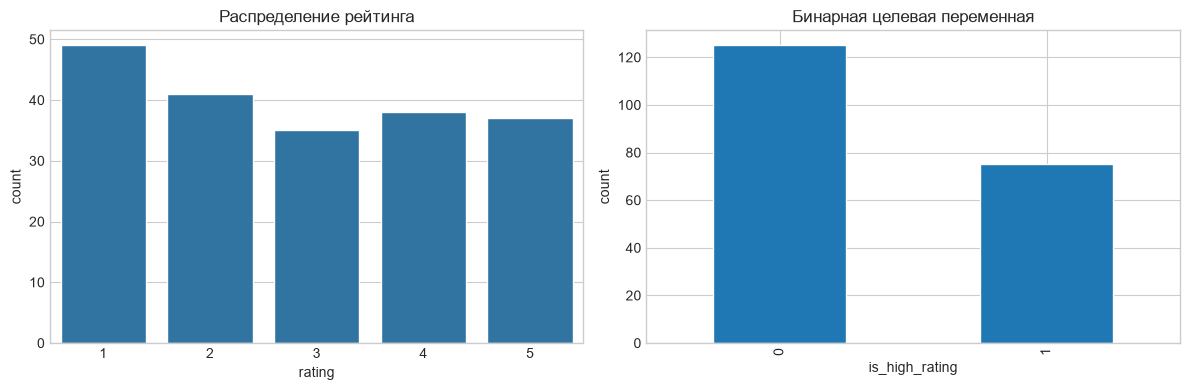

           rating   price_gbp  is_high_rating
count  200.000000  200.000000      200.000000
mean     2.865000   34.796250        0.375000
std      1.451658   14.119272        0.485338
min      1.000000   10.160000        0.000000
25%      2.000000   21.990000        0.000000
50%      3.000000   35.640000        0.000000
75%      4.000000   46.110000        1.000000
max      5.000000   59.640000        1.000000


In [3]:
assert books['url'].is_unique, 'Повторяющиеся карточки'
assert books['rating'].between(1, 5).all()
books['text'] = books['text'].fillna('').str.strip()
books = books[books['text'].str.len() > 3].copy()
books['is_high_rating'] = (books['rating'] >= 4).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=books, x='rating', ax=axes[0])
axes[0].set_title('Распределение рейтинга')
books['is_high_rating'].value_counts().sort_index().plot.bar(ax=axes[1])
axes[1].set(title='Бинарная целевая переменная', xlabel='is_high_rating', ylabel='count')
plt.tight_layout(); plt.show()
print(books[['rating', 'price_gbp', 'is_high_rating']].describe())

## 3. Train/test и TF–IDF

Откладываем 25% наблюдений со стратификацией. `TfidfVectorizer` использует униграммы и биграммы, английские stop words, `min_df=2`, `max_df=0.90` и `norm=None`, то есть обязательная по условию L2-нормализация TF–IDF отключена. Все преобразования находятся внутри Pipeline, поэтому test не участвует в построении словаря.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    books['text'], books['is_high_rating'], test_size=0.25,
    random_state=SEED, stratify=books['is_high_rating'])

pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        lowercase=True, stop_words='english', ngram_range=(1, 2),
        min_df=2, max_df=0.90, norm=None, sublinear_tf=True)),
    ('model', LogisticRegression(max_iter=3000, class_weight='balanced', random_state=SEED))
])
search = GridSearchCV(
    pipeline, {'model__C': [0.001, 0.01, 0.1, 1, 10]},
    scoring='roc_auc', cv=5, n_jobs=1, return_train_score=True)
search.fit(X_train, y_train)
print('Лучший C:', search.best_params_['model__C'])
print('CV ROC-AUC:', round(search.best_score_, 4))

Лучший C: 10
CV ROC-AUC: 0.5039


## 4. Качество на test

,accuracy,f1,roc_auc,n_train,n_test,best_C
0,0.54,0.2069,0.4499,150,50,10


              precision    recall  f1-score   support

           0      0.600     0.774     0.676        31
           1      0.300     0.158     0.207        19

    accuracy                          0.540        50
   macro avg      0.450     0.466     0.441        50
weighted avg      0.486     0.540     0.498        50



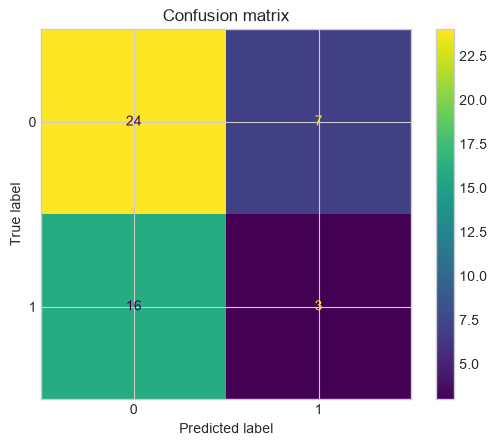

In [5]:
best_model = search.best_estimator_
prediction = best_model.predict(X_test)
probability = best_model.predict_proba(X_test)[:, 1]
metrics = pd.DataFrame([{
    'accuracy': accuracy_score(y_test, prediction),
    'f1': f1_score(y_test, prediction),
    'roc_auc': roc_auc_score(y_test, probability),
    'n_train': len(X_train), 'n_test': len(X_test),
    'best_C': search.best_params_['model__C']
}])
display(metrics.round(4))
print(classification_report(y_test, prediction, digits=3))
ConfusionMatrixDisplay.from_predictions(y_test, prediction)
plt.title('Confusion matrix'); plt.show()
metrics.to_csv(RESULTS_DIR / 'metrics.csv', index=False)

## 5. Топ-50 коэффициентов и интерпретация

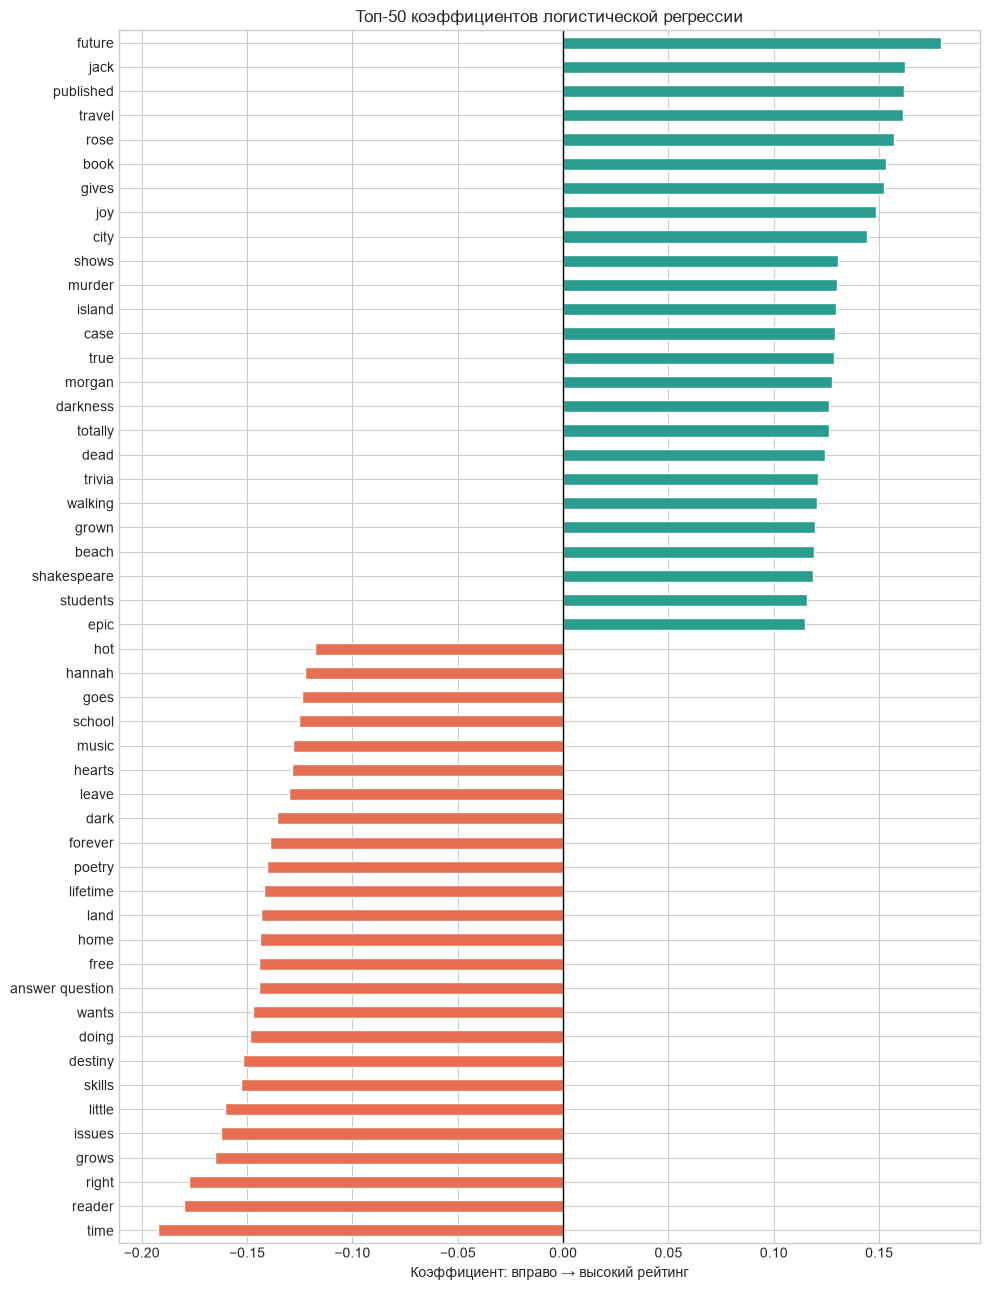

,feature,coefficient
40,shows,0.130583
41,city,0.144041
42,joy,0.148680
43,gives,0.152079
44,book,0.153174
45,rose,0.156801
46,travel,0.161429
47,published,0.161629
48,jack,0.162238
49,future,0.179279


In [6]:
vectorizer = best_model.named_steps['tfidf']
classifier = best_model.named_steps['model']
coefficients = pd.Series(classifier.coef_[0], index=vectorizer.get_feature_names_out())
top = pd.concat([coefficients.nsmallest(25), coefficients.nlargest(25)]).sort_values()
colors = np.where(top.values >= 0, '#2a9d8f', '#e76f51')
plt.figure(figsize=(10, 13))
top.plot.barh(color=colors)
plt.axvline(0, color='black', linewidth=1)
plt.title('Топ-50 коэффициентов логистической регрессии')
plt.xlabel('Коэффициент: вправо → высокий рейтинг')
plt.tight_layout(); plt.savefig(RESULTS_DIR / 'top50_coefficients.png', dpi=160); plt.show()
display(pd.DataFrame({'feature': top.index, 'coefficient': top.values}).tail(10))

## Выводы

Парсер собрал реальный структурированный датасет без API и без частых запросов. Регуляризация выбрана по 5-fold CV, а итоговая оценка рассчитана один раз на отложенных 25%. Положительный коэффициент повышает логарифм шансов рейтинга 4–5, отрицательный — понижает.

Однако коэффициенты нельзя интерпретировать причинно: на учебном сайте рейтинг случаен, выборка мала, а слова редки. Поэтому близкий к 0.5 ROC-AUC ожидаем и честно показывает отсутствие устойчивого текстового сигнала. На реальном книжном сайте следовало бы увеличить выборку и добавить автора, жанр и отзывы.